# Umidade: caracterização e enriquecimento das entradas

Objetivo: verificar se umidade dos sensores de entrada acrescenta informação à reconstrução
de temperatura. Não se usa temperatura nem umidade do alvo nas entradas. O experimento
compara regressão linear sem e com umidade, mantendo candidatos e parâmetros iguais.
Os limites temporais do notebook 03 são preservados. Na comparação entre as duas variantes,
os timestamps são idênticos, mesmo quando a disponibilidade da umidade exigir um subconjunto.
A avaliação é complementar: o teste já foi observado em análises anteriores; não há seleção
ou ajuste de hiperparâmetros a partir de seu erro.

**Estado:** análise executada com extrações reais em 31/10/2026. As consultas,
os CSVs e seus hashes estão preservados em `data/raw/questdb/complementares/`.
Mantenha `ATUALIZAR = False` para reproduzir essa extração sem nova consulta.
As saídas e as limitações de interpretação estão registradas ao final do notebook.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "code/sensores.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Execute dentro do projeto.")
BASE = ROOT / "code/tcc"
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from apoio_consultas import consultar_cache

INICIO = pd.Timestamp("2026-06-10T00:00:00Z")
FIM = pd.Timestamp("2026-07-26T00:00:00Z")
GRADE = pd.date_range(INICIO, FIM, freq="5min", inclusive="left", name="timestamp")
RAW = BASE / "data/raw/questdb/complementares"
ATUALIZAR = False
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn

OUT = BASE / "results/umidade"
TABLES, FIGS = OUT / "tabelas", OUT / "figuras"
for p in [OUT, TABLES, FIGS]:
    p.mkdir(parents=True, exist_ok=True)
IDS = [1, 48, 887, 891, 86782, 86789, 86790, 86791, 86793]
DATA_FILE = BASE / "data/processed/temperaturas_1006_5min_completas.csv"
config03 = json.loads((BASE / "results/experimentos/configuracao_execucao.json").read_text())
assert hashlib.sha256(DATA_FILE.read_bytes()).hexdigest() == config03["sha256_dados"]


## 1. Inventário e extração agregada
As contagens incluem registros nulos. A consulta por cinco minutos preserva mínimos, máximos e contagens para auditar validade.

In [2]:
sql_inventario = "SELECT sensor_id, sensor_model, count(*) AS total, min(measured_in) AS inicio, max(measured_in) AS fim, min(humidity) AS minimo, max(humidity) AS maximo FROM sensor_humidity WHERE environment = '1006' AND measured_in >= '2026-06-10T00:00:00Z' AND measured_in < '2026-07-26T00:00:00Z' GROUP BY sensor_id, sensor_model ORDER BY sensor_id"
inventario = consultar_cache(sql_inventario, RAW / "inventario_umidade.csv", ATUALIZAR)
inventario = inventario.rename(columns={"total": "registros", "inicio": "primeiro", "fim": "ultimo"})
inventario.to_csv(TABLES / "inventario_umidade.csv", index=False)
display(inventario)


,sensor_id,sensor_model,registros,primeiro,ultimo,minimo,maximo
0,1,DHT22,159001,2026-06-10T01:43:24.154000Z,2026-07-25T12:09:52.256000Z,40.7,77.9
1,15,DHT22,27383,2026-06-22T17:31:40.654000Z,2026-07-02T15:41:08.223000Z,NaN,NaN
2,48,DHT22,178345,2026-06-10T01:43:31.867000Z,2026-07-25T10:42:54.748000Z,38.6,77.9
3,86782,DHT22,159470,2026-06-10T01:43:30.466000Z,2026-07-25T13:41:04.384000Z,36.7,79.8
4,86789,DHT22,190391,2026-06-10T01:43:29.740000Z,2026-07-25T11:38:08.445000Z,41.4,79.9
5,86790,DHT22,190332,2026-06-10T01:43:29.997000Z,2026-07-25T10:32:48.368000Z,39.3,74.3
6,86791,DHT22,190433,2026-06-10T01:43:21.412000Z,2026-07-25T11:51:09.974000Z,41.1,77.6
7,86793,DHT22,190763,2026-06-10T01:43:20.313000Z,2026-07-25T13:26:25.184000Z,40.6,85.9
8,887,DHT22,190330,2026-06-10T01:43:21.827000Z,2026-07-25T11:01:11.521000Z,42.9,78.3
9,891,DHT22,189418,2026-06-10T01:43:43.557000Z,2026-07-25T13:03:52.353000Z,45.4,82.0


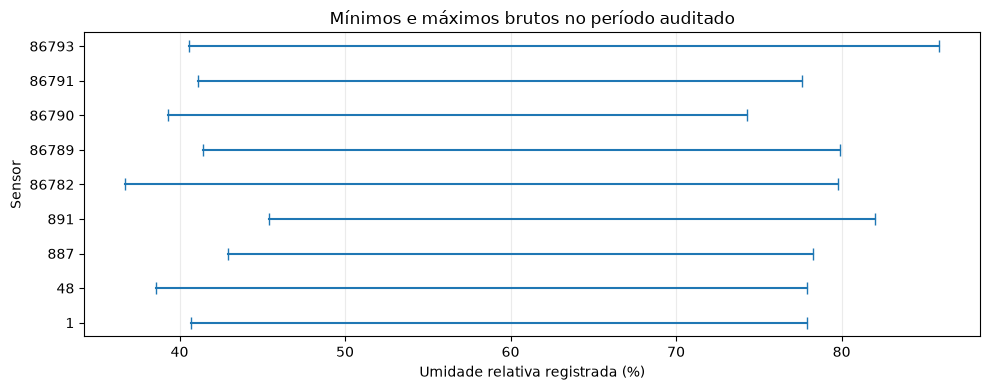

In [3]:
# Caracterização já possível com a auditoria real, sem série temporal.
faixas = inventario[inventario.sensor_id.astype(int).isin(IDS)].copy()
faixas.sensor_id = faixas.sensor_id.astype(int)
faixas = faixas.set_index("sensor_id").reindex(IDS)
fig, ax = plt.subplots(figsize=(10, 4))
for i, sid in enumerate(IDS):
    ax.plot([faixas.loc[sid, "minimo"], faixas.loc[sid, "maximo"]], [i, i],
            color="tab:blue", marker="|", markersize=9)
ax.set(yticks=range(len(IDS)), yticklabels=[str(s) for s in IDS],
       xlabel="Umidade relativa registrada (%)", ylabel="Sensor",
       title="Mínimos e máximos brutos no período auditado")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(FIGS / f"faixas_umidade_auditadas.{ext}", dpi=240, bbox_inches="tight")
plt.show()


In [4]:
ids_sql = ", ".join(f"'{s}'" for s in IDS)
sql = f"""SELECT measured_in, sensor_id, avg(humidity) AS umidade_media,
 min(humidity) AS minimo, max(humidity) AS maximo,
 count(*) AS quantidade, count(humidity) AS quantidade_validos
 FROM sensor_humidity WHERE environment = '1006'
 AND measured_in >= '2026-06-10T00:00:00Z' AND measured_in < '2026-07-26T00:00:00Z'
 AND sensor_id IN ({ids_sql}) SAMPLE BY 5m ORDER BY measured_in, sensor_id"""
ARQUIVO_UMIDADE = RAW / "umidade_1006_5min.csv"
extraidos = consultar_cache(sql, ARQUIVO_UMIDADE, ATUALIZAR)
if extraidos.empty:
    raise RuntimeError("Sem dados de umidade no período.")
print("Pares sensor–janela retornados:", len(extraidos))


Pares sensor–janela retornados: 116475


## 2. Grade temporal, disponibilidade e associação com temperatura

Os dispositivos foram identificados como DHT22; a umidade é tratada como relativa em porcentagem,
coerente com o tipo de sensor e a escala registrada. Janelas com mínimo ou máximo fora de [0,100]
são identificadas e excluídas integralmente; não há imputação. Essa validação não comprova
calibração metrológica. Correlações usadas abaixo como diagnóstico são calculadas no treinamento.


In [5]:
h = extraidos.copy()
h.measured_in = pd.to_datetime(h.measured_in, utc=True, errors="raise")
h.sensor_id = pd.to_numeric(h.sensor_id, errors="raise").astype(int)
for c in ["umidade_media", "minimo", "maximo", "quantidade", "quantidade_validos"]:
    h[c] = pd.to_numeric(h[c], errors="raise")
assert set(h.sensor_id) == set(IDS)
assert not h.duplicated(["measured_in", "sensor_id"]).any()
assert h.measured_in.between(INICIO, FIM, inclusive="left").all()
assert h.measured_in.eq(h.measured_in.dt.floor("5min")).all()
invalidos = (h.minimo < 0) | (h.maximo > 100) | (h.quantidade_validos == 0)
h[invalidos].to_csv(TABLES / "janelas_invalidas_umidade.csv", index=False)
h.loc[invalidos, "umidade_media"] = np.nan
assert np.isfinite(h.umidade_media.dropna().to_numpy()).all()
umidade = h.pivot(index="measured_in", columns="sensor_id", values="umidade_media").reindex(index=GRADE, columns=IDS)
umidade.to_csv(BASE / "data/processed/umidade_1006_5min.csv", index_label="timestamp")

temperatura = pd.read_csv(DATA_FILE, index_col="timestamp")
temperatura.index = pd.to_datetime(temperatura.index, utc=True)
temperatura.columns = temperatura.columns.astype(int)
corte = pd.Timestamp(config03["inicio_teste_utc"])
resumo_h = pd.DataFrame({"sensor_id": IDS,
    "janelas_validas": umidade.notna().sum().to_numpy(),
    "janelas_ausentes": umidade.isna().sum().to_numpy(),
    "cobertura_pct": 100 * umidade.notna().mean().to_numpy(),
    "media_ur_pct": umidade.mean().to_numpy(), "desvio_ur_pp": umidade.std().to_numpy(),
    "min_ur_pct": umidade.min().to_numpy(), "max_ur_pct": umidade.max().to_numpy()})
resumo_h["pearson_temp_umid_treino"] = [temperatura.loc[temperatura.index < corte, sid].corr(umidade[sid]) for sid in IDS]
resumo_h.to_csv(TABLES / "resumo_umidade.csv", index=False)
display(resumo_h.round(3))
print("Janelas completas para nove umidades:", len(umidade.dropna()))
print("Janelas com valores inválidos:", int(invalidos.sum()))


,sensor_id,janelas_validas,janelas_ausentes,cobertura_pct,media_ur_pct,desvio_ur_pp,min_ur_pct,max_ur_pct,pearson_temp_umid_treino
0,1,12944,304,97.705,56.655,8.470,40.733,77.508,-0.382
1,48,12919,329,97.517,54.520,8.061,38.893,76.873,-0.185
2,887,12931,317,97.607,57.664,7.483,43.033,78.200,-0.250
3,891,12954,294,97.781,59.796,7.086,45.475,79.388,-0.108
4,86782,12963,285,97.849,56.572,8.669,37.638,79.477,-0.446
5,86789,12938,310,97.660,57.142,8.250,41.507,79.667,-0.316
6,86790,12925,323,97.562,53.980,7.252,39.308,73.907,-0.252
7,86791,12941,307,97.683,56.747,7.247,41.347,77.083,-0.205
8,86793,12960,288,97.826,59.159,8.189,40.807,85.154,-0.359


Janelas completas para nove umidades: 12916
Janelas com valores inválidos: 0


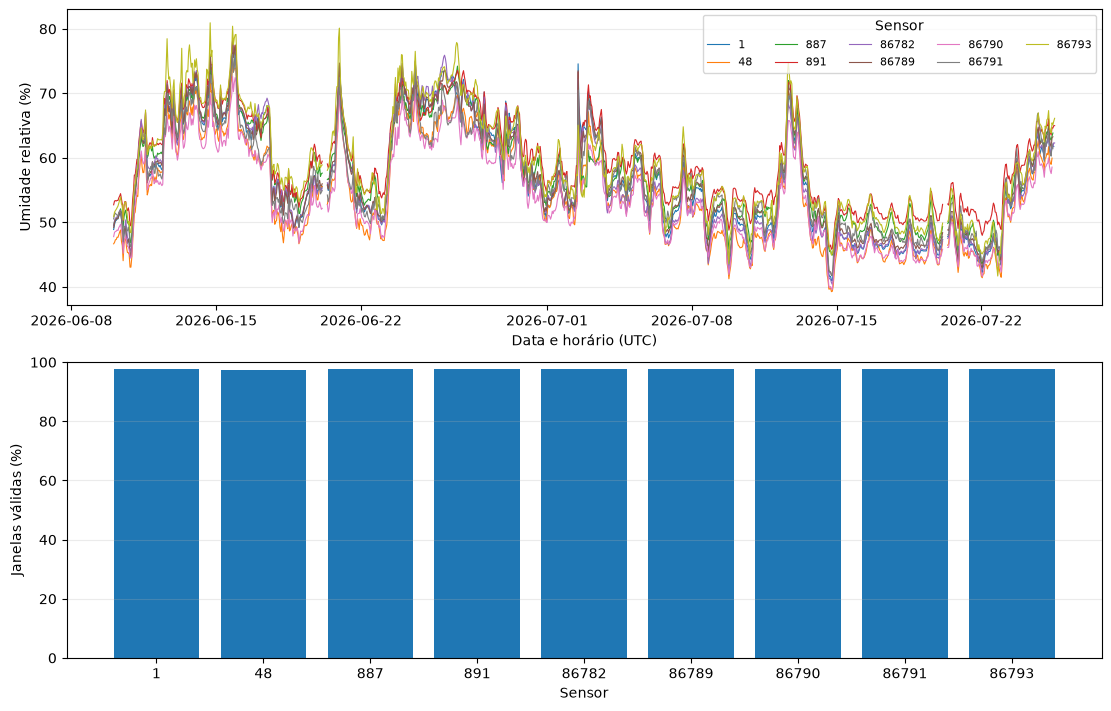

In [6]:
fig, eixos = plt.subplots(2, 1, figsize=(11, 7), layout="constrained")
for sid in IDS:
    # Médias horárias somente para legibilidade, sem preencher lacunas.
    eixos[0].plot(umidade[sid].resample("1h").mean(), lw=0.8, label=str(sid))
eixos[0].set(ylabel="Umidade relativa (%)", xlabel="Data e horário (UTC)")
eixos[0].legend(title="Sensor", ncol=5, fontsize=8)
eixos[1].bar(resumo_h.sensor_id.astype(str), resumo_h.cobertura_pct)
eixos[1].set(ylabel="Janelas válidas (%)", xlabel="Sensor", ylim=(0, 100))
for ax in eixos:
    ax.grid(axis="y", alpha=0.25)
for ext in ["png", "pdf"]:
    fig.savefig(FIGS / f"caracterizacao_umidade.{ext}", dpi=240, bbox_inches="tight")
plt.show()


## 3. Comparação pareada: temperaturas ou temperaturas + umidades

Mantêm-se as fronteiras temporais do notebook 03. Para cada alvo, selecionam-se janelas
com as oito temperaturas de entrada, a temperatura de referência e as oito umidades de entrada.
A disponibilidade da umidade do alvo não participa dessa seleção. Ambas as variantes são
reajustadas no mesmo treinamento retido e avaliadas nas mesmas linhas de teste. Assim,
a diferença mede o acréscimo das variáveis e não a mudança do conjunto de avaliação.
Não se faz novo corte 70%/30% após excluir as janelas sem umidade.


In [7]:
metricas, previsoes, amostras = [], [], []
for alvo in IDS:
    entradas = [s for s in IDS if s != alvo]
    u = umidade.reindex(temperatura.index)[entradas]
    completos = u.notna().all(axis=1)
    idx_treino = temperatura.index[(temperatura.index < corte) & completos]
    idx_teste = temperatura.index[(temperatura.index >= corte) & completos]
    if len(idx_treino) < 100 or len(idx_teste) < 100:
        raise RuntimeError(f"Amostras insuficientes para {alvo}.")
    X_t = temperatura[entradas].add_prefix("T_")
    X_th = X_t.join(u.add_prefix("H_"))
    amostras.append({"sensor_alvo": alvo, "n_treino": len(idx_treino), "n_teste": len(idx_teste),
                    "perdas_treino": config03["n_treino"] - len(idx_treino),
                    "perdas_teste": config03["n_teste"] - len(idx_teste)})
    for variante, X in [("Temperaturas", X_t), ("Temperaturas e umidades", X_th)]:
        assert all(c not in X for c in [f"T_{alvo}", f"H_{alvo}"])
        modelo = LinearRegression().fit(X.loc[idx_treino], temperatura.loc[idx_treino, alvo])
        y = temperatura.loc[idx_teste, alvo]
        pred = modelo.predict(X.loc[idx_teste])
        metricas.append({"sensor_alvo": alvo, "variante": variante,
                         "n_treino": len(idx_treino), "n_teste": len(idx_teste),
                         "n_variaveis": X.shape[1], "sensores_entrada": json.dumps(entradas),
                         "MAE": mean_absolute_error(y, pred),
                         "RMSE": np.sqrt(mean_squared_error(y, pred)), "R2": r2_score(y, pred)})
        previsoes.append(pd.DataFrame({"timestamp": idx_teste, "sensor_alvo": alvo,
                         "variante": variante, "real": y.to_numpy(), "estimada": pred}))
metricas = pd.DataFrame(metricas)
previsoes = pd.concat(previsoes, ignore_index=True)
amostras = pd.DataFrame(amostras)
for alvo, g in previsoes.groupby("sensor_alvo"):
    sub = list(g.groupby("variante"))
    assert tuple(sub[0][1].timestamp) == tuple(sub[1][1].timestamp)
resumo_modelos = metricas.groupby("variante", as_index=False).agg(
    MAE_medio=("MAE", "mean"), RMSE_medio=("RMSE", "mean"), R2_medio=("R2", "mean"))
delta = metricas.pivot(index="sensor_alvo", columns="variante", values="MAE")
delta["delta_MAE_mais_umidade"] = delta["Temperaturas e umidades"] - delta["Temperaturas"]
metricas.to_csv(TABLES / "metricas_enriquecimento.csv", index=False)
resumo_modelos.to_csv(TABLES / "resumo_enriquecimento.csv", index=False)
amostras.to_csv(TABLES / "amostras_pareadas.csv", index=False)
delta.to_csv(TABLES / "delta_mae_por_alvo.csv")
previsoes.to_csv(OUT / "previsoes_enriquecimento.csv.gz", index=False, compression="gzip")
display(amostras)
display(resumo_modelos.round(6))
display(delta.round(6))


,sensor_alvo,n_treino,n_teste,perdas_treino,perdas_teste
0,1,9024,3866,0,2
1,48,9024,3868,0,0
2,887,9024,3866,0,2
3,891,9024,3866,0,2
4,86782,9024,3866,0,2
5,86789,9024,3866,0,2
6,86790,9024,3866,0,2
7,86791,9024,3866,0,2
8,86793,9024,3866,0,2


,variante,MAE_medio,RMSE_medio,R2_medio
0,Temperaturas,0.256679,0.324878,0.849784
1,Temperaturas e umidades,0.253427,0.322503,0.857143


variante,Temperaturas,Temperaturas e umidades,delta_MAE_mais_umidade
sensor_alvo,,,
1,0.239554,0.228366,-0.011188
48,0.154843,0.169223,0.014380
887,0.276117,0.240761,-0.035356
891,0.386904,0.335412,-0.051492
86782,0.399431,0.450711,0.051280
86789,0.089566,0.118563,0.028997
86790,0.145011,0.147555,0.002545
86791,0.378531,0.360909,-0.017621
86793,0.240160,0.229342,-0.010818


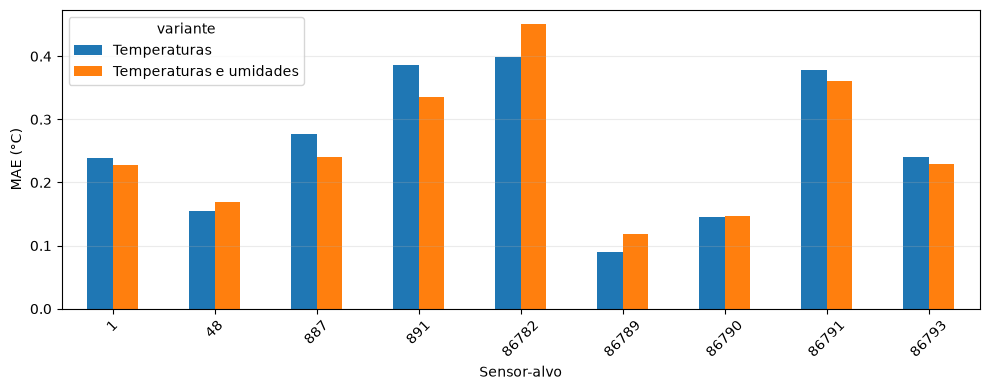

Caracterização e comparação concluídas: /home/gustavomoura/Documents/temperatureMonitoring/code/tcc/results/umidade


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
metricas.pivot(index="sensor_alvo", columns="variante", values="MAE").reindex(IDS).plot.bar(ax=ax)
ax.set(xlabel="Sensor-alvo", ylabel="MAE (°C)")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
for ext in ["png", "pdf"]:
    fig.savefig(FIGS / f"efeito_umidade.{ext}", dpi=240, bbox_inches="tight")
plt.show()
config = {"executado_em_utc": pd.Timestamp.now(tz="UTC").isoformat(), "ids": IDS,
          "sha256_temperatura": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
          "sha256_extracao_umidade": hashlib.sha256(ARQUIVO_UMIDADE.read_bytes()).hexdigest(),
          "inicio_teste_utc": corte.isoformat(), "imputacao": False,
          "criterio_umidade": "Exclusão integral de janela se mínimo<0, máximo>100 ou contagem válida=0",
          "umidade_alvo_usada": False, "parametros": LinearRegression().get_params(),
          "n_avaliacoes": len(metricas), "janelas_invalidas": int(invalidos.sum()),
          "versoes": {"python": platform.python_version(), "pandas": pd.__version__,
                      "numpy": np.__version__, "scikit_learn": sklearn.__version__}}
(OUT / "configuracao_umidade.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("Caracterização e comparação concluídas:", OUT)
